# Plotting Soundings with BUFKIT Forecast Model Data

In [1]:
# import sounderpy
import sounderpy as spy

/home/kjgil/sounderpy/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### **Understanding SounderPy Functionality** 

**To get model forecast data via BUFKIT, we need to use the** `get_bufkit_data()` **function**

**Reading the documentation on BUFKIT data access may prove useful before using this notebook: *https://sounderpy.app/docs/reference/gettingdata.html#model-forecast-data-bufkit-profiles***

In [2]:
################################ THE FUNCTION ###################################
# to get bufkit data, we need to use the `get_bufkit_data()` function
# `get_bufkit_data(model, station, fcst_hour, run_year=None, run_month=None, run_day=None, run_hour=None)`
################################################################################


########################## TYPES OF BUFKIT DATA ################################
# we can access archived model forecasts from the GFS, NAM, NAMNEST, RAP, HRRR & RRFS
# or most recent run forecasts from the GFS, RAP, HRRR & RRFS
# (NCEP decommissioned the NAM & NAMNEST on November 2, 2026, so they are archive only;
# the SREF & HIRESW are discontinued and no longer available)
################################################################################


########################## WHERE DATA IS AVAILABLE #############################
# NOTE: bufkit forecast data is *only available at specific BUFKIT site locations*
# you can find them here: https://sounderpy.app/docs/reference/gettingdata.html#available-bufkit-sites
################################################################################


############################# LETS GET SOME DATA ###############################
# to get archived forecasts we need every kwarg. (a kwarg is a Keyword Argument, like 'year', and 'station')
# the line below will get us a 12z GFS forecast from 08/05/2023 at forecast hour 6 for bufkit site KMOP:

# clean_data = spy.get_bufkit_data('gfs', 'kmop', 6, '2023', '08', '05', '12')

# to get the most recent forecasts we use the same function, but we *don't need a year, month, day or hour kwarg!*
# you just need a model, station and forecast hour.
# this will get you the most recent HRRR run, at forecast hour 6, for 
# site `KAMA` (AMARILLO ARPT(AWOS)):


clean_data = spy.get_bufkit_data('hrrr', 'kama', 6)

> BUFKIT DATA ACCESS FUNCTION
   ---------------------------------


    > COMPLETE --------
    > RUNTIME: 00:00:00
    > SUMMARY: 12Z HRRR F06 for KAMA, AMARILLO ARPT(AWOS) at 11-23-2026-18Z


 
    > THERMODYNAMICS --------------------------------------------- 
    --- SBCAPE: 0.0 | MUCAPE: 0.0 | MLCAPE: 0.0 | MUECAPE: --
    --- MU 0-3: 0.0 | MU 0-6: 0.0 | SB 0-3: 0.0 | SB 0-6: 0.0
 
    > KINEMATICS ------------------------------------------------- 
    --- 0-500 SRW: 25.1 knot | 0-500 SWV: 0.002 | 0-500 SHEAR: 3.1 | 0-500 SRH: 11.4
    --- 1-3km SRW: 12.7 knot | 1-3km SWV: 0.004 | 1-3km SHEAR: 13.8 | | 1-3km SRH: 56.5
 


In [3]:
# Lets check out the BUFKIT data that we just accessed
# and stored in the `clean_data` variable: 

# `clean_data` is a python dictionary of 'clean' vertical profile data
# it comes with temperature, dewpoint, pressure, height, u and v
# as well as a number of useful 'meta data'

clean_data

{'p': <Quantity([897.9 895.3 890.4 882.1 869.8 854.2 835.7 815.7 794.2 770.2 744.1 715.6
  684.9 651.8 616.3 578.4 538.1 498.7 462.7 430.1 400.4 373.  348.  325.2
  304.4 285.5 268.2 252.  237.2 223.5 209.6 195.8 181.9 168.  154.1 140.2
  126.3 112.4  98.6  85.7  75.3  66.9  59.1], 'hectopascal')>,
 'z': <Quantity([ 1108.02  1131.7   1176.41  1252.48  1366.11  1511.89  1688.04  1883.24
   2098.06  2343.41  2617.22  2926.75  3274.78  3666.8   4106.51  4599.64
   5153.76  5728.81  6286.77  6822.93  7340.48  7844.77  8329.47  8794.35
   9239.77  9664.6  10072.47 10472.79 10856.01 11227.12 11621.92 12037.69
  12489.26 12981.52 13520.1  14111.14 14763.19 15488.78 16301.47 17171.8
  17980.88 18725.78 19504.32], 'meter')>,
 'T': <Quantity([  5.64   5.04   4.44   3.44   2.34   0.94   1.84   1.84   0.54  -1.56
   -3.06  -2.36  -2.06  -3.86  -6.26  -9.36 -12.86 -16.86 -20.76 -24.26
  -27.96 -32.36 -36.66 -40.96 -44.96 -48.56 -51.96 -55.36 -58.36 -61.76
  -64.46 -64.76 -62.56 -60.66 -59.56 -59.56

-----

#### **LETS PLOT THE DATA ON A SOUNDING AND HODOGRAPH**

> SOUNDING PLOTTER FUNCTION
  ---------------------------------
    > PREPARING DATA


/home/kjgil/sounderpy/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:1686: UserWarning: Warning: converting a masked element to nan.
  return interp_func(x, xp, fp, left, right)


/home/kjgil/sounderpy/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/kjgil/sounderpy/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/kjgil/sounderpy/src/sounderpy/calc.py:976: Warning: MU-ECAPE could not be computed for this sounding (calculation error)
  warnings.warn("MU-ECAPE could not be computed for this sounding (calculation error)", Warning)
/home/kjgil/sounderpy/src/sounderpy/calc.py:983: Warning: ML-ECAPE could not be computed for this sounding (calculation error)
  warnings.warn("ML-ECAPE could not be computed for this sounding (calculation error)", Warning)
/home/kjgil/sounderpy/src/sounderpy/calc.py:990: Warning: SB-ECAPE could not be computed for this sounding (calculation error)
  warnings.warn("SB-ECAPE could not be computed for this sounding 

    > BUILDING SKEW-T LOG-P DIAGRAM
    > BUILDING HODOGRAPH
    > BUILDING MAP INSET


    > BUILDING ACCESSORY PLOTS
    > PLOTTING SOUNDING PARAMETERS
    > FIGURE LOADING...


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


    > COMPLETE --------
    > RUNTIME: 00:00:07


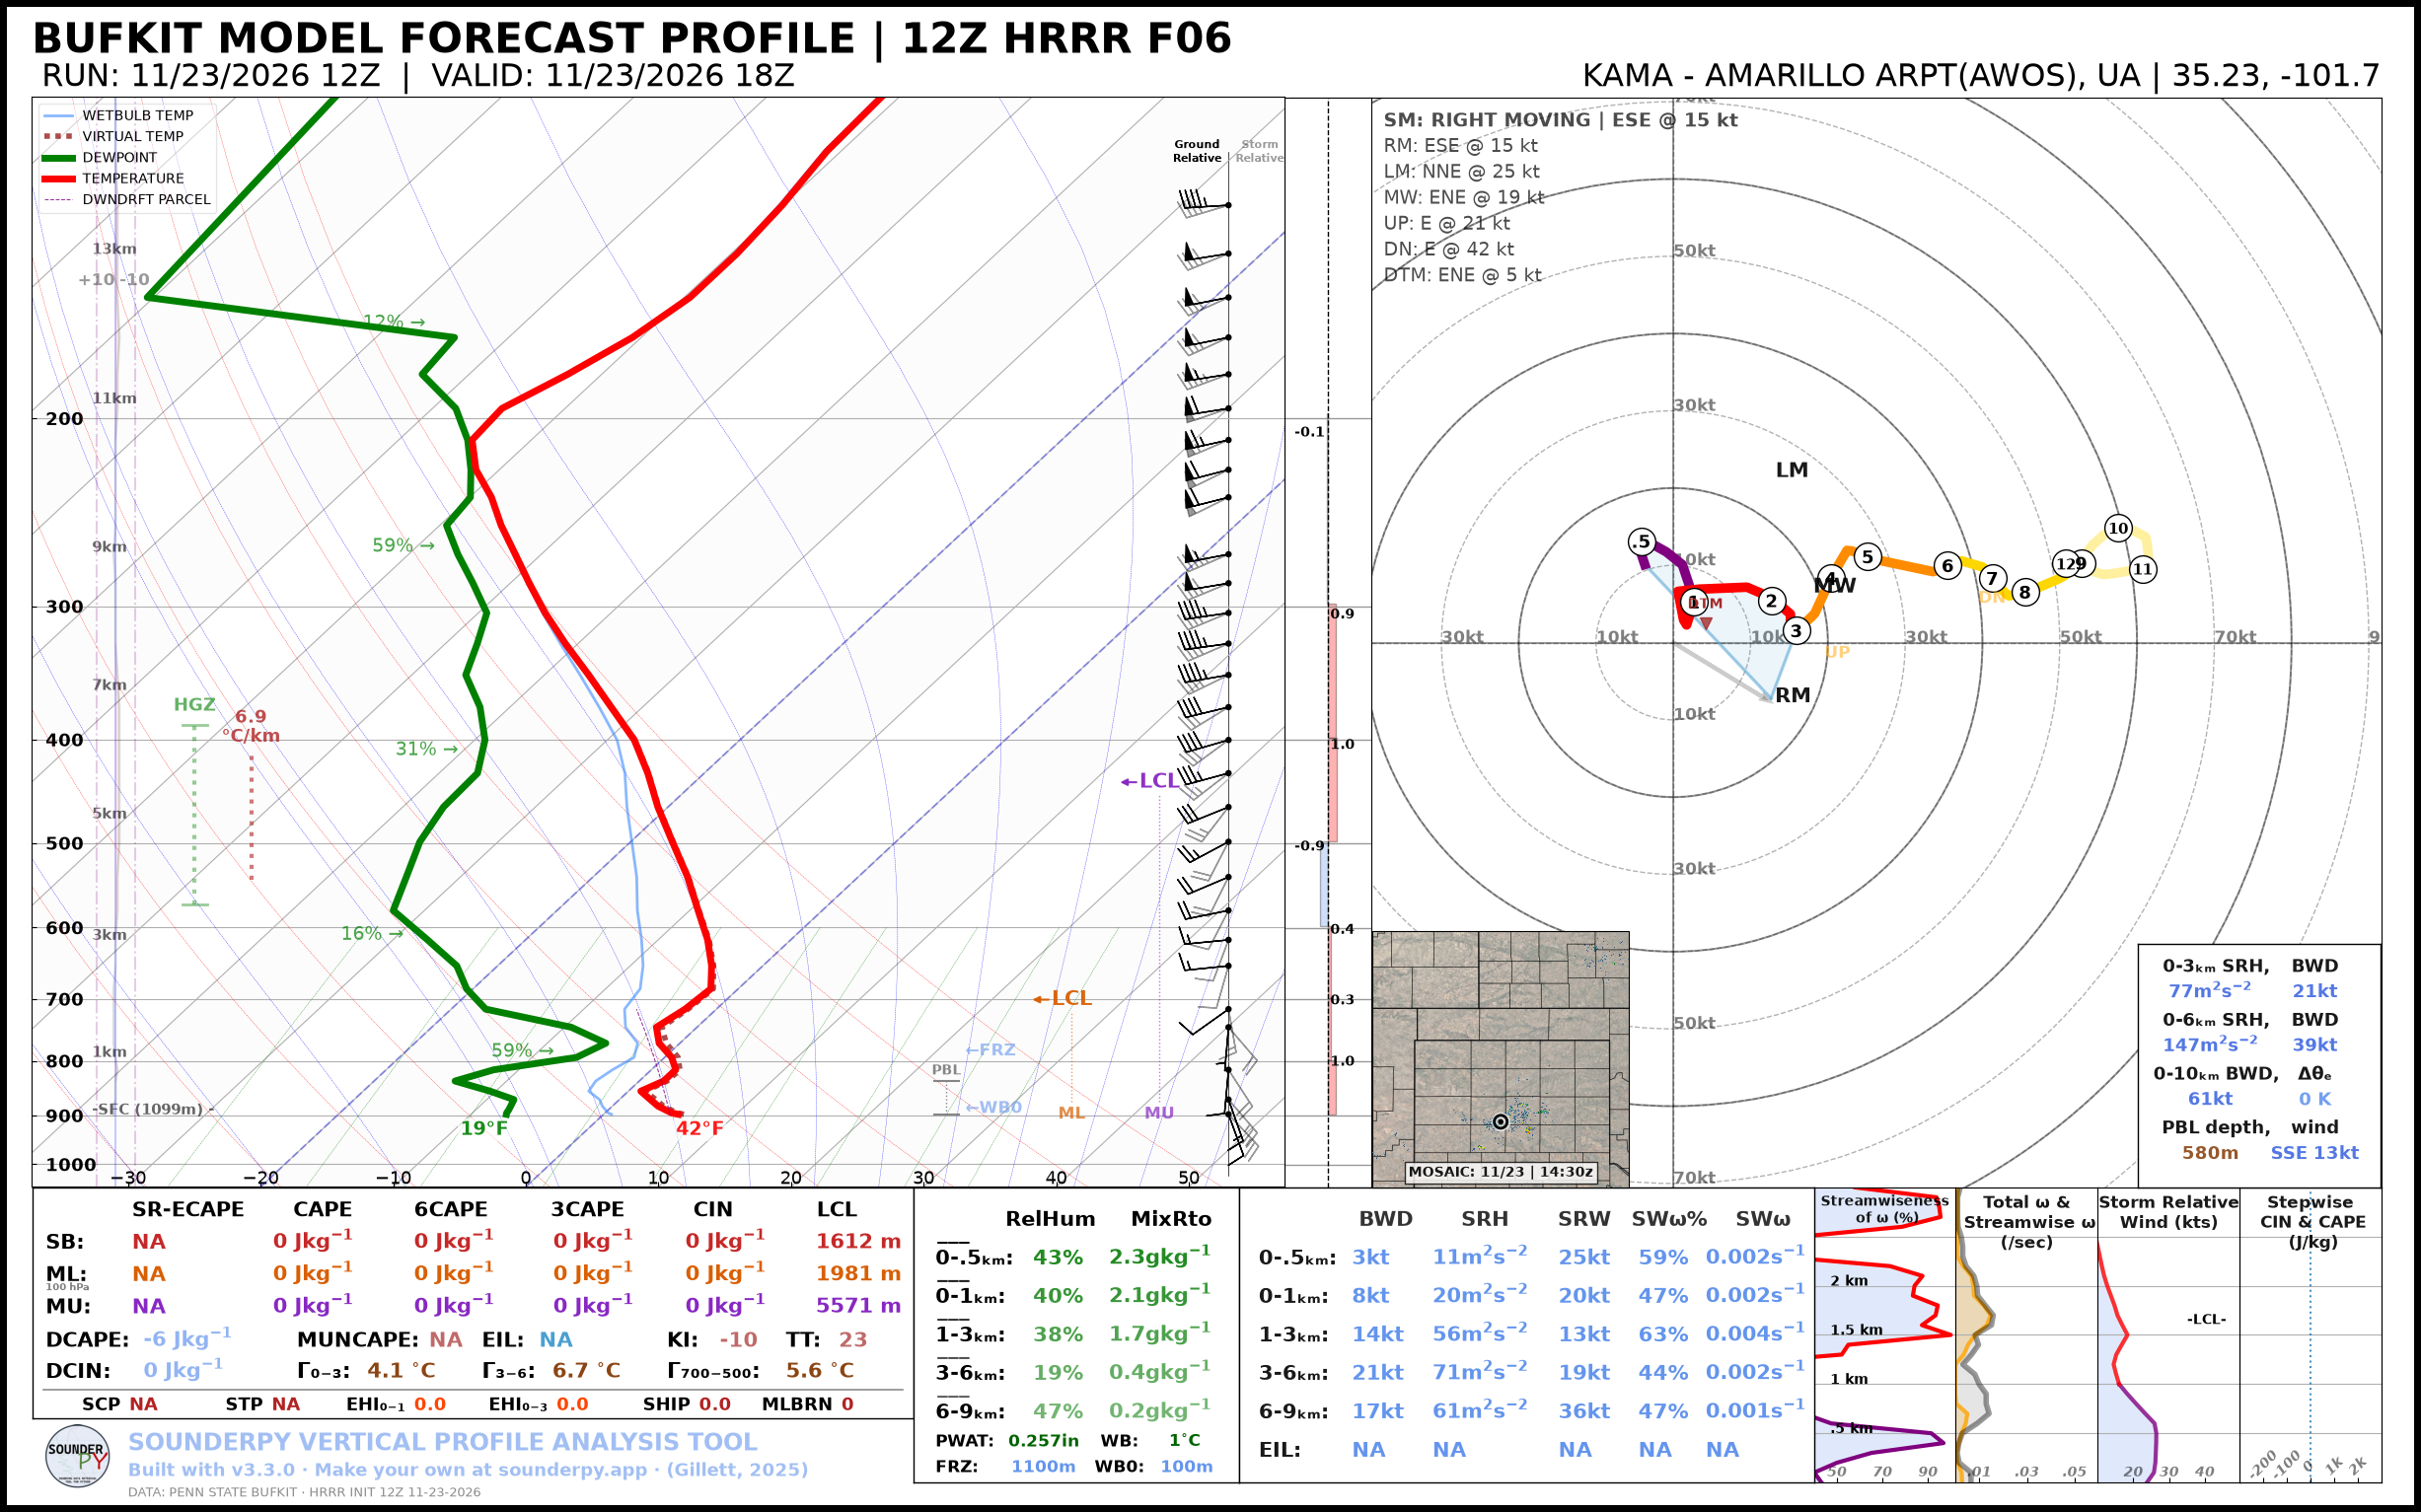

In [4]:
# lets make a sounding!
spy.build_sounding(clean_data)